# AF6: Aprendizaje Supervisado, Arbol de decisión

Hora: N1-N3



*   Reynaldo Aldape Sonora 2028750
*   Sergio Daniel Suárez Aguirre 2127902


*   Angel Esteban Pedraza Gomez 2097528







In [ ]:
#<<<<<<<<<<<<<<<Cargar librerias>>>>>>>>>>>>>>>
# Importa la función que carga el conjunto de datos de cáncer de mama (Breast Cancer Wisconsin) incluido en scikit-learn
from sklearn.datasets import load_breast_cancer
# Importa la función que divide los datos en conjuntos de entrenamiento y prueba
from sklearn.model_selection import train_test_split
# Importa el clasificador de árbol de decisión y la función para dibujar el árbol
from sklearn.tree import DecisionTreeClassifier, plot_tree
# Importa las métricas de evaluación: matriz de confusión, exactitud y reporte de clasificación
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
# Importa pyplot de matplotlib para crear y mostrar gráficas
import matplotlib.pyplot as plt

In [ ]:
#<<<<<<<<<<<<<<<<<<<Cargar datos>>>>>>>>>>>>>>>>>>>>>>
# Carga el dataset completo (atributos, etiquetas, nombres de columnas y clases) en un objeto tipo diccionario
datos = load_breast_cancer()
# Guarda en X la matriz con los atributos (características de los tumores) de cada paciente
X = datos.data
# Guarda en y las etiquetas reales (0 = maligno, 1 = benigno)
y = datos.target

#Verificar datos
# Mensaje de confirmación de que los datos se cargaron
print("Nombre del conjunto de datos cargado correctamente.")
# Muestra la forma de X: (número de muestras, número de atributos)
print("Forma de X (Atributos):", X.shape)
# Muestra la forma de y: (número de muestras,)
print("Forma de y (Etiquetas):", y.shape)

Nombre del conjunto de datos cargado correctamente.
Forma de X (Atributos): (569, 30)
Forma de y (Etiquetas): (569,)


In [ ]:
#<<<<<<<<<<<<<<<Reprocesamiento de datos>>>>>>>>>>>>>>>
# Divide los datos y asigna los resultados a cuatro variables: atributos y etiquetas de entrenamiento y de prueba
train_data, test_data, train_labels, test_label = train_test_split(
    # Atributos que se van a dividir
    X,
    # Etiquetas que se van a dividir con la misma partición
    y,
    # 20% de los datos se usa para prueba y 80% para entrenamiento
    test_size=0.20,
    # Semilla fija para que la división aleatoria sea siempre la misma (reproducible)
    random_state=42
)

# Muestra la forma de los datos de entrenamiento (filas, columnas)
print("Datos de entrenamiento:", train_data.shape)
# Muestra la forma de los datos de prueba (filas, columnas)
print("Datos de prueba:", test_data.shape)

Datos de entrenamiento: (455, 30)
Datos de prueba: (114, 30)


In [ ]:
#<<<<<<<<<<<<<<<<Selección y entrenamiento del modelo>>>>>>>>>>>>>>
# Crea el modelo de árbol de decisión; random_state=42 hace que los resultados sean reproducibles
modelo = DecisionTreeClassifier(random_state=42)
#Entrenar el modelo
# Entrena el árbol: aprende reglas de decisión a partir de los atributos y etiquetas de entrenamiento
modelo.fit(train_data, train_labels)

DecisionTreeClassifier(random_state=42)

In [ ]:
#<<<<<<<<<<<Prueba del modelo>>>>>>>>>>>>>
# Usa el modelo entrenado para predecir la clase de los datos de prueba (que no vio al entrenar)
predicciones = modelo.predict(test_data)
#Matris de confusión
# Imprime un encabezado para identificar la sección
print("--- Matriz de Confusión ---")
# Compara etiquetas reales vs. predicciones: muestra aciertos y errores por clase (filas = real, columnas = predicho)
print(confusion_matrix(test_label, predicciones))

--- Matriz de Confusión ---
[[40  3]
 [ 3 68]]


In [ ]:
#Exactitud y Reporte de clasificación
# Calcula la exactitud: proporción de predicciones correctas sobre el total de datos de prueba
exactitud = accuracy_score(test_label, predicciones)
# Imprime la exactitud con 4 decimales (el \n agrega un salto de línea antes)
print(f"\nPrecisión (Accuracy): {exactitud:.4f}")
# Imprime un encabezado para el reporte
print("\n--- Reporte de Clasificación ---")
# Muestra precision, recall y f1-score por clase, usando los nombres de las clases (maligno/benigno)
print(classification_report(test_label, predicciones, target_names=datos.target_names))


Precisión (Accuracy): 0.9474

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



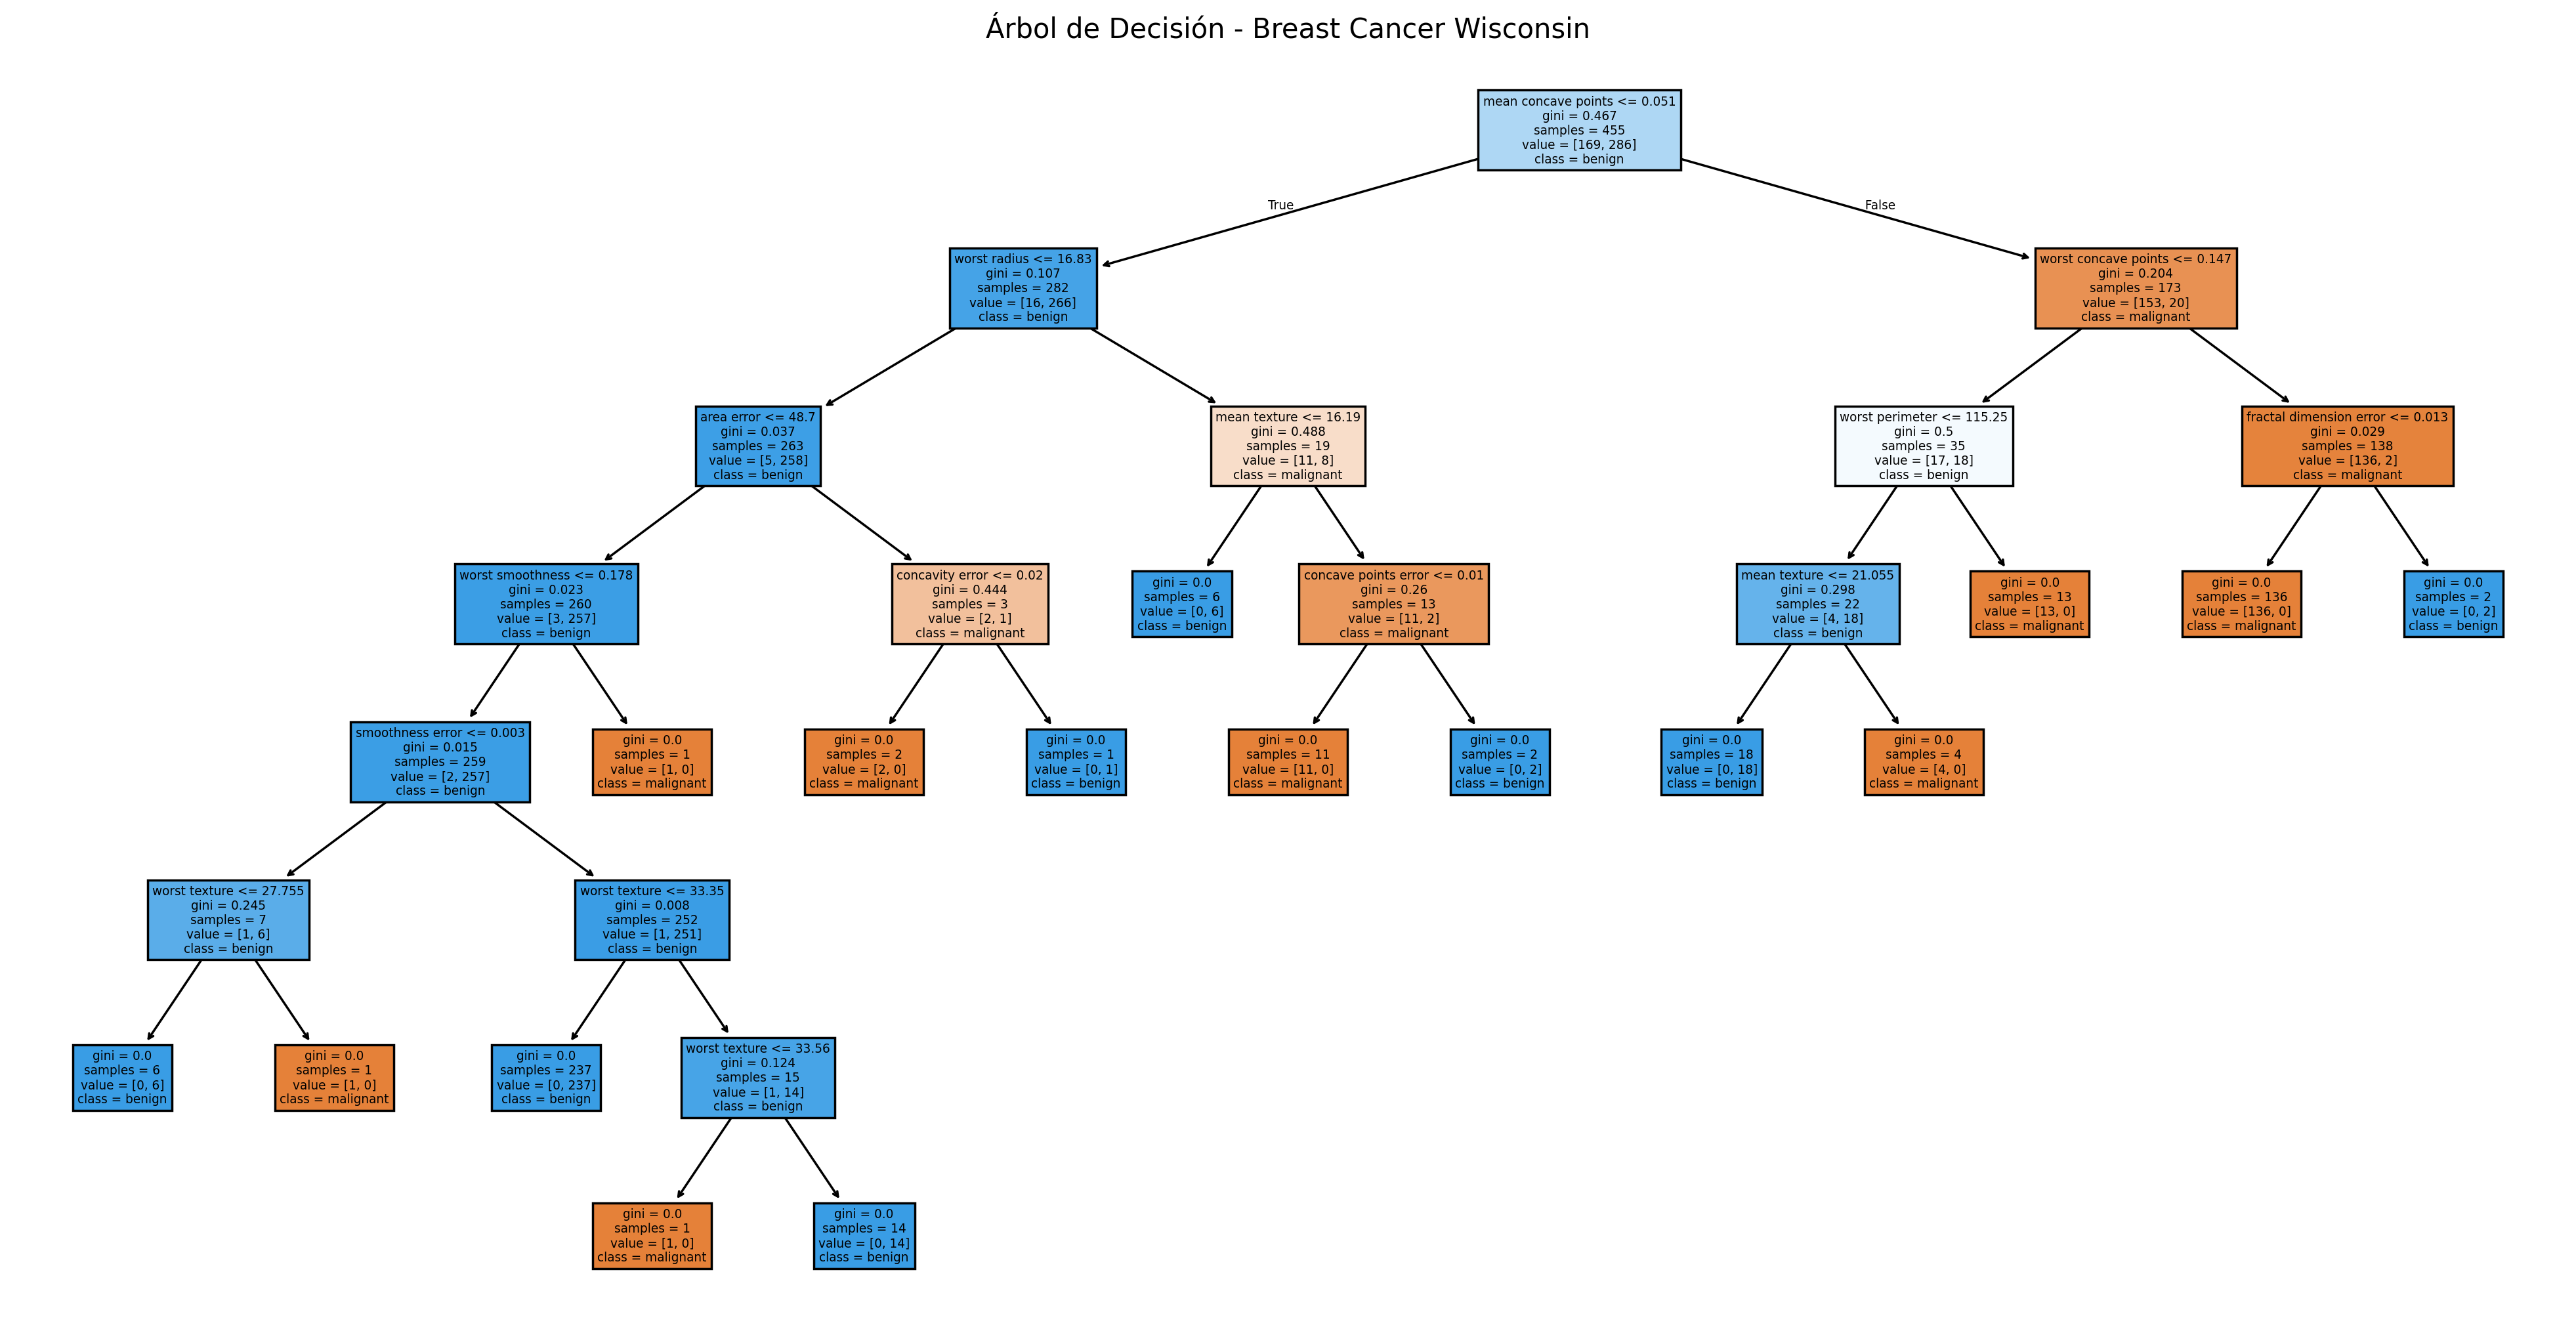

In [ ]:
#Gráfica con DPI=250
# Crea una figura grande (20x10 pulgadas) con alta resolución (250 DPI) para que el árbol se vea legible
plt.figure(figsize=(20, 10), dpi=250)
# Dibuja el árbol de decisión entrenado
plot_tree(
    # Modelo entrenado que se va a graficar
    modelo,
    # Nombres de los atributos para mostrarlos en cada nodo de decisión
    feature_names=datos.feature_names,
    # Nombres de las clases (maligno/benigno) para mostrarlos en los nodos
    class_names=datos.target_names,
    # Colorea los nodos según la clase predominante
    filled=True
)
# Agrega un título a la gráfica
plt.title("Árbol de Decisión - Breast Cancer Wisconsin")
# Muestra la gráfica en pantalla
plt.show()